# Eksperymenty z Whisperem (krok 3)

Który Whisper daje najlepszy kompromis między czasem a jakością transkrypcji? Porównujemy na `dev`:

- **model**: small, medium, large-v3-turbo, large-v3,
- **hotwords**: bez / wszystkie 94 terminy z `terms_it.csv` / tylko nazwy własne (kategorie `tool` i `technology`, 44 nazwy; dla small i turbo),
- **filtr halucynacji**: brak / reguły / reguły + pewność modelu; działa na zapisanych wynikach, więc nie wymaga ponownej transkrypcji.

Wszystkie przebiegi mają podpowiedź z przerywnikami („yyy”) wybraną w `01_whisper_baseline`. `test` zostaje na końcowy pomiar wybranych konfiguracji.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter
from asr import BASE_PARAMS, VERBATIM_PROMPT, hotwords, load_recordings, load_result, run
from evaluate import score, term_errors, term_lexicon

/opt/miniconda3/envs/interview-sim/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Siatka eksperymentu: każdy model z podpowiedzią „yyy”, bez i z hotwords, tylko na dev
MODELS = ["small", "medium", "large-v3-turbo", "large-v3"]  # od najmniejszego do największego
VERBATIM = {**BASE_PARAMS, "initial_prompt": VERBATIM_PROMPT}
VARIANTS = {
    "verbatim": VERBATIM,
    "verbatim_hotwords": {**VERBATIM, "hotwords": hotwords()},
}
# krótka lista: tylko nazwy produktów, których Whisper nie ma skąd znać; wybrana regułą, a nie z błędów na dev,
# żeby nie dopasować jej do tych 7 nagrań
NAMES_VARIANT = "verbatim_hotwords_names"
NAMES_PARAMS = {**VERBATIM, "hotwords": hotwords({"tool", "technology"})}
NAMES_MODELS = ["small", "large-v3-turbo"]
dev_ids = [rec["file_id"] for rec in load_recordings() if rec["split"] == "dev"]

In [3]:
# Transkrypcja do results/asr/<model>__<wariant>/; gotowe pliki są pomijane
# Za pierwszym razem pobiera modele medium (~1,5 GB) i large-v3 (~3 GB). Czasy są porównywalne tylko wtedy,
# gdy komputer nie liczy w tym czasie nic innego; żeby zmierzyć od nowa, usuń folder danego przebiegu
run_dirs = {}
for model_name in MODELS:
    for variant, params in VARIANTS.items():
        run_dirs[model_name, variant] = run(model_name, variant, params, dev_ids)
for model_name in NAMES_MODELS:
    run_dirs[model_name, NAMES_VARIANT] = run(model_name, NAMES_VARIANT, NAMES_PARAMS, dev_ids)

## Filtr halucynacji

Obecne reguły odrzucają segmenty niemożliwie szybkie (> 8 słów/s) i znane frazy z napisów, ale przepuszczają np. „Cóż, PATRESKA” na końcu `rec_001`. Whisper zapisuje przy każdym segmencie swoją pewność (`avg_logprob`, im bliżej zera, tym pewniej). Próg dobieramy z segmentów o najniższej pewności na `dev`.

In [4]:
# Segmenty z najniższą pewnością ze wszystkich przebiegów na dev; to_end = ile sekund przed końcem nagrania się kończą
segments = pd.DataFrame([
    {"model": model_name, "variant": variant, "id": file_id, "avg_logprob": s["avg_logprob"],
     "start": s["start"], "to_end": result["duration"] - s["end"], "text": s["text"].strip()}
    for (model_name, variant), out_dir in run_dirs.items()
    for file_id in dev_ids
    for result in [load_result(out_dir, file_id)]
    for s in result["segments"]
])
segments.sort_values("avg_logprob").head(20)

,model,variant,id,avg_logprob,start,to_end,text
289,large-v3-turbo,verbatim_hotwords,rec_001,-4.559677,67.26,6.228000,po pierwsze.
290,large-v3-turbo,verbatim_hotwords,rec_001,-4.559677,68.80,3.488000,Jest to akl سbe.
273,large-v3-turbo,verbatim_hotwords,rec_201,-4.228853,30.04,31.580000,"z dostępo widać, bo do w XVII, i nie pełnów o ..."
454,large-v3-turbo,verbatim_hotwords_names,rec_103,-3.787869,85.26,0.321313,AA dobrażał mesmo sle provokeowimy WG.
455,large-v3-turbo,verbatim_hotwords_names,rec_103,-3.787869,85.74,0.021312,Ça reservacja uzdrażonebữa w tle na przykład z...
291,large-v3-turbo,verbatim_hotwords,rec_001,-3.364998,70.88,1.708000,Zeskot
284,large-v3-turbo,verbatim_hotwords,rec_103,-3.137248,36.74,26.021313,".Cu prawda, czy no, że nie ma, jak podzielona ..."
459,large-v3-turbo,verbatim_hotwords_names,rec_001,-2.912291,71.96,2.168000,od GO pans!
460,large-v3-turbo,verbatim_hotwords_names,rec_001,-2.912291,72.34,1.708000,od
440,large-v3-turbo,verbatim_hotwords_names,rec_201,-2.723974,51.94,20.220000,"na. Miami, czyli w jednym z informacji, że prz..."


In [5]:
MIN_LOGPROB = -1.0  # uzasadnienie w komórce tekstowej z wnioskami na końcu notatnika

## Wyniki

Wszystkie liczby są zbiorcze dla całego `dev` (suma błędów / suma słów). `rtf` to czas: sekundy obliczeń na sekundę nagrania, bez ładowania modelu. `tp`, `fn`, `fp` to trafione, pominięte i zmyślone terminy.

In [6]:
lexicon = term_lexicon()
FILTERS = {
    "brak": {"use_filter": False},
    "reguły": {},
    "reguły + pewność": {"min_logprob": MIN_LOGPROB},
}
results = pd.DataFrame([
    {"model": model_name, "variant": variant, "filter": filter_name,
     **score(out_dir, dev_ids, lexicon, **filter_kwargs)}
    for (model_name, variant), out_dir in run_dirs.items()
    for filter_name, filter_kwargs in FILTERS.items()
])

# Wpływ filtra: WER każdego przebiegu przy trzech wersjach filtra
results.pivot_table(index=["model", "variant"], columns="filter", values="wer", sort=False).style.format("{:.1%}")

In [7]:
# Główne porównanie, z pełnym filtrem
FILTER = "reguły + pewność"
table = results[results["filter"] == FILTER].drop(columns="filter").set_index(["model", "variant"])
percent = ["wer", "cer", "precision", "recall", "f1"]
table.style.format({**{col: "{:.1%}" for col in percent}, "rtf": "{:.2f}"})

## Czas a jakość

Każdy punkt to jeden przebieg. Kolor to rozmiar modelu (jaśniejszy = mniejszy), kółko = bez hotwords, trójkąt = wszystkie terminy, kwadrat = tylko nazwy własne; linie prowadzą od wariantu bez hotwords do wariantów z hotwords tego samego modelu. Najlepsze konfiguracje są na lewo (szybciej) i niżej na wykresie WER albo wyżej na wykresie F1.

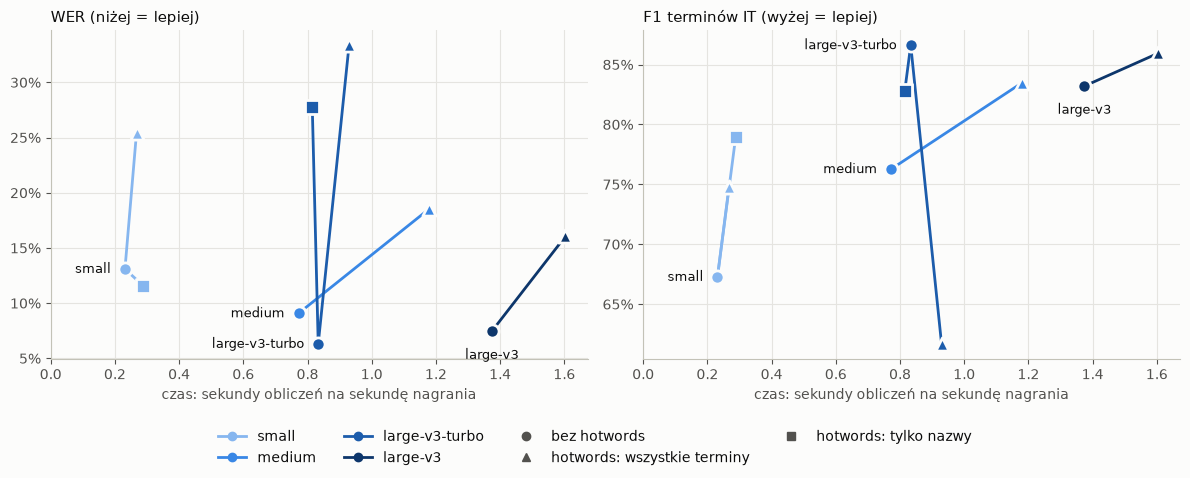

In [8]:
COLORS = dict(zip(MODELS, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))  # jeden odcień, jasny → ciemny
MARKERS = {"verbatim": "o", "verbatim_hotwords": "^", NAMES_VARIANT: "s"}
MARKER_LABELS = {"verbatim": "bez hotwords", "verbatim_hotwords": "hotwords: wszystkie terminy",
                 NAMES_VARIANT: "hotwords: tylko nazwy"}
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e4e0"
# podpis po lewej od punktu; large-v3 pod punktem, bo po lewej wpada na trójkąt medium
LABEL_LEFT = {"xytext": (-10, 0), "ha": "right", "va": "center"}
LABEL_POSITIONS = {"large-v3": {"xytext": (0, -12), "ha": "center", "va": "top"}}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), facecolor=SURFACE)
for ax, metric, title in zip(axes, ["wer", "f1"], ["WER (niżej = lepiej)", "F1 terminów IT (wyżej = lepiej)"]):
    ax.set_facecolor(SURFACE)
    for model_name in MODELS:
        rows = table.loc[model_name]
        base = rows.loc["verbatim"]
        for variant in rows.index.drop("verbatim"):
            ax.plot([base["rtf"], rows.loc[variant, "rtf"]], [base[metric], rows.loc[variant, metric]],
                    color=COLORS[model_name], linewidth=2, zorder=1)
        for variant in rows.index:
            ax.scatter(rows.loc[variant, "rtf"], rows.loc[variant, metric], marker=MARKERS[variant], s=90,
                       color=COLORS[model_name], edgecolor=SURFACE, linewidth=2, zorder=2)
        ax.annotate(model_name, (rows.loc["verbatim", "rtf"], rows.loc["verbatim", metric]),
                    textcoords="offset points", fontsize=9, color=INK, **LABEL_POSITIONS.get(model_name, LABEL_LEFT))
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("czas: sekundy obliczeń na sekundę nagrania", color=MUTED)
    ax.set_xlim(left=0)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")

handles = [Line2D([], [], color=COLORS[m], marker="o", linewidth=2, label=m) for m in MODELS]
handles += [Line2D([], [], color=MUTED, marker=MARKERS[v], linestyle="", label=label)
            for v, label in MARKER_LABELS.items()]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, labelcolor=INK)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

## Terminy: co naprawiły, a co zepsuły hotwords

Główne ryzyko hotwords to zmyślone terminy, więc najpierw ich lista (pusta tabela = brak zmyślonych). Potem: ile razy dany termin został pominięty bez hotwords i z nimi, łącznie we wszystkich 4 modelach.

In [9]:
errors = pd.DataFrame([
    {"model": model_name, "variant": variant, **row}
    for (model_name, variant), out_dir in run_dirs.items()
    for row in term_errors(out_dir, dev_ids, lexicon, **FILTERS[FILTER])
])
errors[errors["error"] == "false"]

,model,variant,id,error,term,said,written
35,small,verbatim,rec_005,false,NaN,sprincie,sprintie
92,medium,verbatim,rec_005,false,NaN,sprincie,sprintu
112,medium,verbatim_hotwords,rec_003,false,NaN,od,ltsowe
113,medium,verbatim_hotwords,rec_005,false,NaN,sprincie,sprintu
170,large-v3-turbo,verbatim_hotwords,rec_003,false,NaN,∅,review
171,large-v3-turbo,verbatim_hotwords,rec_003,false,NaN,∅,develop
188,large-v3,verbatim,rec_001,false,NaN,∅,backend
199,large-v3,verbatim_hotwords,rec_103,false,NaN,pytań,railway
244,large-v3-turbo,verbatim_hotwords_names,rec_103,false,NaN,∅,pgvector
245,large-v3-turbo,verbatim_hotwords_names,rec_103,false,NaN,o,pgvector


In [10]:
(errors[errors["error"] == "missed"]
 .pivot_table(index="term", columns="variant", values="id", aggfunc="count", fill_value=0)
 .sort_values("verbatim", ascending=False))

variant,verbatim,verbatim_hotwords,verbatim_hotwords_names
term,,,
Vocare,11,0,0
branch,9,11,4
POC,7,1,2
pgvector,7,3,2
merge,6,7,3
Hangfire,6,5,2
Vercel,4,4,2
PostgreSQL,4,2,1
hotfix,4,7,2


## Wnioski (dev, 7 nagrań)

1. **Najlepszy model: large-v3-turbo bez hotwords.** Ma najniższy WER (6,3%) i najwyższe F1 terminów (86,6%), a jest szybszy od large-v3. large-v3 nie jest lepszy (WER 7,5%, F1 83,2%), za to zostawia najwięcej przerywników (44 z 97).
2. **Hotwords pomagają tylko jako krótka lista i tylko w small.**
   - Pełna lista (94 terminy) psuje wszystkie modele: WER rośnie 2–5 razy, bo Whisper pomija całe fragmenty mowy (medium, `rec_201`: 58 pominiętych słów zamiast 6).
   - Krótka lista samych nazw własnych (kategorie `tool` i `technology`, 44 nazwy) poprawia small: WER 13,1% → 11,6%, F1 67,3% → 79,0%, bez zmyślonych terminów. Lista jest wybrana regułą, a nie z błędów na dev, więc nie jest dopasowana do tych nagrań.
   - Turbo z hotwords jest niestabilny przy obu listach. Zapętla się („to jest to, yyy” 7 razy z rzędu, „i tak dalej” 7 razy) i produkuje bełkot w kilku językach (krótka lista: WER 6,3% → 27,7%). Prawdopodobna przyczyna: turbo ma odchudzony dekoder (4 warstwy zamiast 32 w large-v3), który łatwo wybić z rytmu dodatkowym tekstem w podpowiedzi.
3. **small z krótką listą jest ok. 3 razy szybszy od turbo i traci do niego 7,6 pkt F1** (79,0% wobec 86,6%). To punkt wyjścia do pytania „słabszy model + Bielik”: korekta musiałaby odrobić te 7,6 pkt, a jej czas doliczamy do czasu smalla.
4. **Filtr halucynacji.** Reguły są potrzebne: turbo bez filtra ma WER 12,3%, z filtrem 6,3% (seria halucynacji na końcu `rec_001`). Próg pewności `avg_logprob < −1,0` to domyślny próg samego Whispera. Łapie bełkot przy hotwords i nie usuwa prawdziwej mowy, bo najniższa pewność prawdziwego segmentu na dev to ok. −0,57. Ostrzejszy próg −0,65 złapałby jeszcze „KONIEC”, ale leży za blisko prawdziwej mowy i byłby dopasowany do 7 nagrań. Pętle turbo z hotwords mają zwykłą pewność (ok. −0,2), więc tego filtr nie naprawi.
5. **Czasy są orientacyjne.** MacBook Air nie ma wentylatora i pod długim obciążeniem zwalnia. Przebiegi szły po kolei (small → medium → turbo → large-v3), więc późniejsze mają zawyżone czasy: turbo w osobnym uruchomieniu (`01_whisper_baseline`) miał 0,65 s/s, a tu 0,83. Pewne jest tylko to, że small jest wyraźnie najszybszy, a large-v3 najwolniejszy. Kolejność medium i turbo nie jest rozstrzygnięta.
6. **Whisper nie jest w pełni powtarzalny.** Przy niskiej pewności losuje kolejne próby (temperature fallback), dlatego dwa przebiegi turbo z tymi samymi ustawieniami dały różne końcówki `rec_001`.

**Dwa punkty odniesienia dla kroku 4 (Bielik):**
- large-v3-turbo bez hotwords: najlepsza jakość,
- small z krótką listą hotwords: najszybszy.

Oba mają podpowiedź z „yyy” i filtr (reguły + `avg_logprob < −1,0`).
